# Morphological Dilation & Erosion

Comparing four structuring elements: Square (7x7), Cross (7x7), Vertical Line (1x9), and Horizontal Line (9x1).

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### 1. Structuring Elements
- **Square (7x7)**: All 8 directions (`cv2.MORPH_RECT`)
- **Cross (7x7)**: 4 cardinal directions (`cv2.MORPH_CROSS`)
- **Vertical Line (1x9)**: Vertical only (`1x9`)
- **Horizontal Line (9x1)**: Horizontal only (`9x1`)

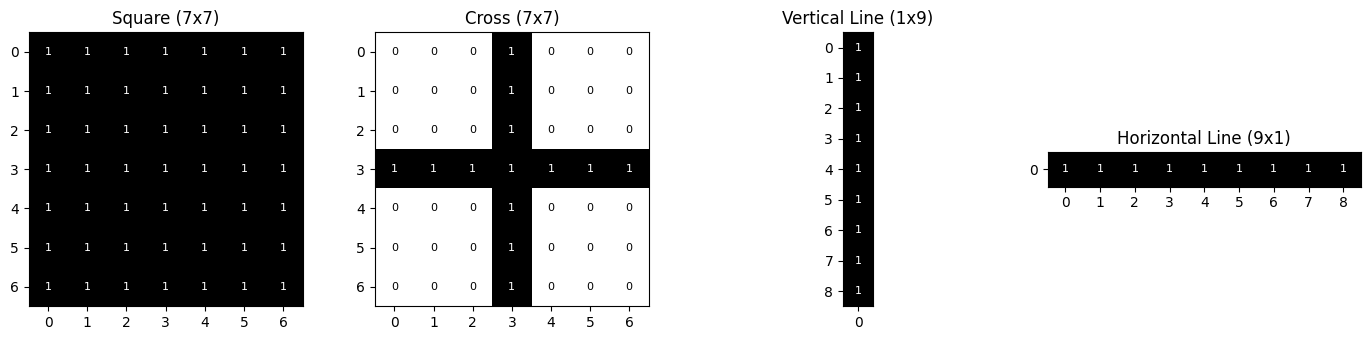

In [2]:
se_sq   = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))
se_cr   = cv2.getStructuringElement(cv2.MORPH_CROSS, (7, 7))
se_vert = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 9))
se_horz = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 1))

kernels = [
    ('Square (7x7)', se_sq),
    ('Cross (7x7)', se_cr),
    ('Vertical Line (1x9)', se_vert),
    ('Horizontal Line (9x1)', se_horz)
]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, (title, k) in zip(axes, kernels):
    ax.imshow(k, cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(k.shape[1]))
    ax.set_yticks(range(k.shape[0]))
    for i in range(k.shape[0]):
        for j in range(k.shape[1]):
            ax.text(j, i, str(k[i, j]), ha='center', va='center',
                    color='white' if k[i, j] == 1 else 'black', fontsize=8)
plt.tight_layout()
plt.show()

### 2. Dilation (`cv2.dilate`)
Expands foreground (bridges gaps):
- **Square (7x7)**: Bridges horizontal & vertical gaps
- **Cross (7x7)**: Bridges cardinal gaps (no diagonal growth)
- **Vertical Line (1x9)**: Bridges vertical gaps only
- **Horizontal Line (9x1)**: Bridges horizontal gaps only

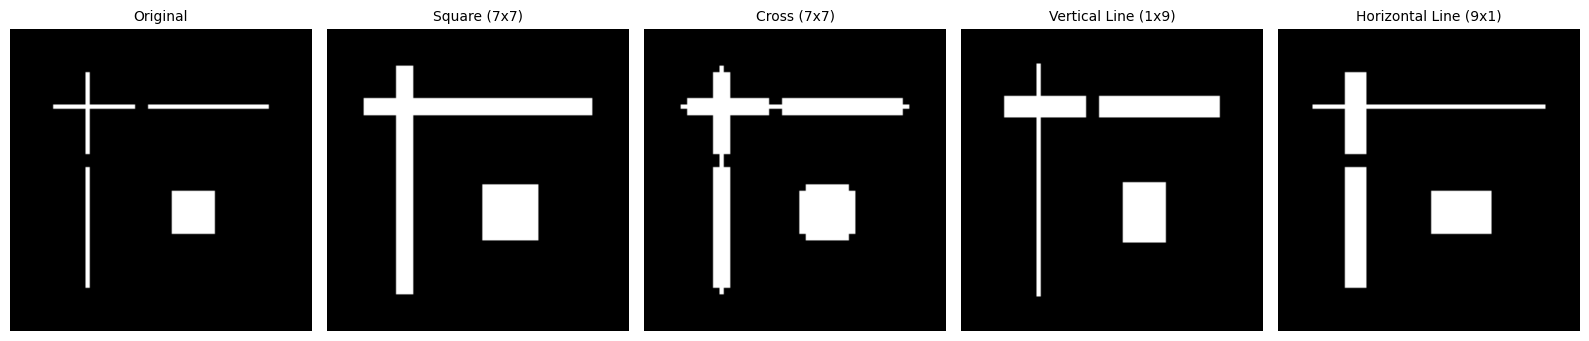

In [3]:
# Test pattern: broken lines and solid square
test_img = np.zeros((140, 140), dtype=np.uint8)
test_img[35:37, 20:58] = 255
test_img[35:37, 64:120] = 255  # Broken horizontal line (gap from x=58 to x=64)
test_img[20:58, 35:37] = 255
test_img[64:120, 35:37] = 255  # Broken vertical line (gap from y=58 to y=64)
test_img[75:95, 75:95] = 255   # Solid square

# Dilation
d_square   = cv2.dilate(test_img, se_sq)
d_cross    = cv2.dilate(test_img, se_cr)
d_vertical = cv2.dilate(test_img, se_vert)
d_horiz    = cv2.dilate(test_img, se_horz)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
titles = ['Original', 'Square (7x7)', 'Cross (7x7)', 'Vertical Line (1x9)', 'Horizontal Line (9x1)']
imgs = [test_img, d_square, d_cross, d_vertical, d_horiz]

for ax, t, im in zip(axes, titles, imgs):
    ax.imshow(im, cmap='gray')
    ax.set_title(t, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 3. Erosion (`cv2.erode`)
Shrinks foreground (removes thin features):
- **Square (7x7)**: Eliminates both thin lines, shrinks square
- **Cross (7x7)**: Eliminates lines except at intersections
- **Vertical Line (1x9)**: Removes horizontal lines, keeps vertical line
- **Horizontal Line (9x1)**: Removes vertical lines, keeps horizontal line

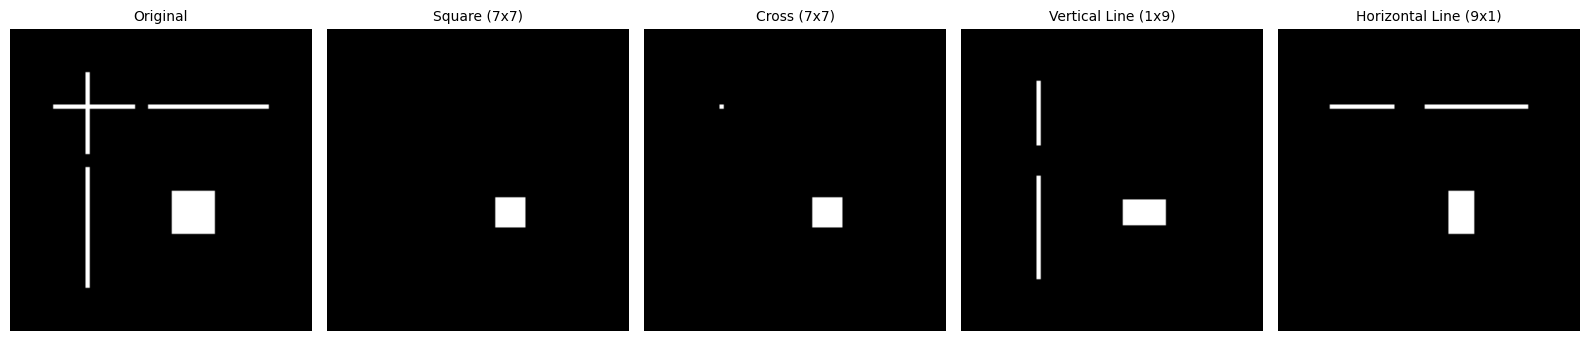

In [4]:
# Erosion
e_square   = cv2.erode(test_img, se_sq)
e_cross    = cv2.erode(test_img, se_cr)
e_vertical = cv2.erode(test_img, se_vert)
e_horiz    = cv2.erode(test_img, se_horz)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
titles = ['Original', 'Square (7x7)', 'Cross (7x7)', 'Vertical Line (1x9)', 'Horizontal Line (9x1)']
imgs = [test_img, e_square, e_cross, e_vertical, e_horiz]

for ax, t, im in zip(axes, titles, imgs):
    ax.imshow(im, cmap='gray')
    ax.set_title(t, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()